In [53]:
import pandas as pd
import numpy as np
from matplotlib.ticker import MaxNLocator
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [54]:
df = pd.read_pickle("./data_features_clustering")
df.columns

Index(['Unnamed: 0', 'id', 'connectionTime', 'disconnectTime',
       'doneChargingTime', 'kWhDelivered', 'sessionID', 'siteID', 'spaceID',
       'stationID', 'timezone', 'userID', 'userInputs', 'endChargingTime',
       'chargingDurationMin', 'blockingDurationMin', 'charging_time_minutes',
       'energy_rate_kW', 'connection_hour', 'disconnect_hour',
       'connection_hour_sin', 'connection_hour_cos', 'disconnect_hour_sin',
       'disconnect_hour_cos', 'connection_isWeekday', 'isRegisteredUser'],
      dtype='object')

In [55]:
df = df.drop(columns=["Unnamed: 0", "id", "connectionTime", "disconnectTime", "doneChargingTime", "sessionID", "siteID", "spaceID",
                       "stationID", 'timezone', 'userID', 'userInputs', 'endChargingTime', 'connection_hour', 'disconnect_hour'])
df.columns

Index(['kWhDelivered', 'chargingDurationMin', 'blockingDurationMin',
       'charging_time_minutes', 'energy_rate_kW', 'connection_hour_sin',
       'connection_hour_cos', 'disconnect_hour_sin', 'disconnect_hour_cos',
       'connection_isWeekday', 'isRegisteredUser'],
      dtype='object')

In [56]:
non_binary_cols = df.columns[0:-2]
scaler = StandardScaler()
scaled_df = df.copy()
scaled_df[non_binary_cols] = scaler.fit_transform(df[non_binary_cols])
scaled_df.head()

,kWhDelivered,chargingDurationMin,blockingDurationMin,charging_time_minutes,energy_rate_kW,connection_hour_sin,connection_hour_cos,disconnect_hour_sin,disconnect_hour_cos,connection_isWeekday,isRegisteredUser
0,1.311224,0.335517,-0.270766,-0.040338,0.205416,0.932076,1.555901,1.733465,-1.360708,1,1
1,2.104488,1.233312,-0.094101,0.651821,0.111639,0.960457,1.280383,0.012960,-0.967805,1,1
2,-0.504321,-0.339395,1.402768,1.043035,-0.192526,0.967958,1.081159,-0.599812,-0.154682,1,1
3,-0.913272,-0.856000,-0.356778,-0.827146,-0.275252,0.968159,1.051212,2.868183,-0.708783,1,1
4,0.168496,0.301825,0.301438,0.447586,-0.113022,0.968172,1.041229,0.228280,-1.113846,1,1


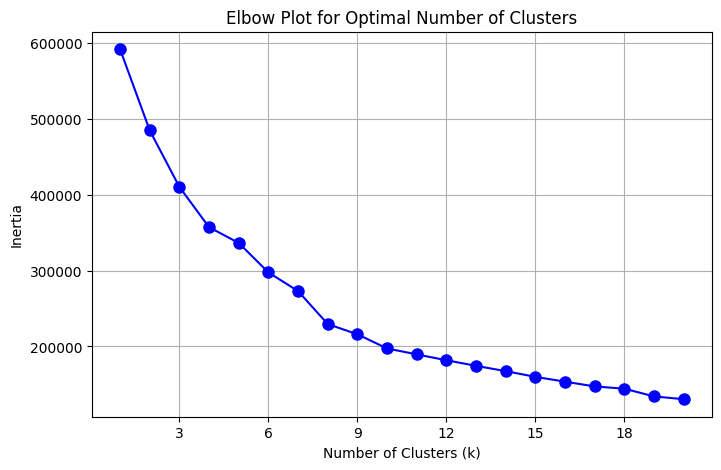

In [57]:
inertia = []
K = range(1, 21)  # Testing from 1 to 20 clusters
for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(scaled_df)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(K, inertia, "bo-", markersize=8)
plt.title("Elbow Plot for Optimal Number of Clusters")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.grid(True)
plt.gca().xaxis.set_major_locator(MaxNLocator(integer=True))
plt.show()

In [59]:
optimal_k = 8  # Chosen based on the elbow plot
kmeans = KMeans(n_clusters=optimal_k, random_state=69)
df['Cluster'] = kmeans.fit_predict(scaled_df)

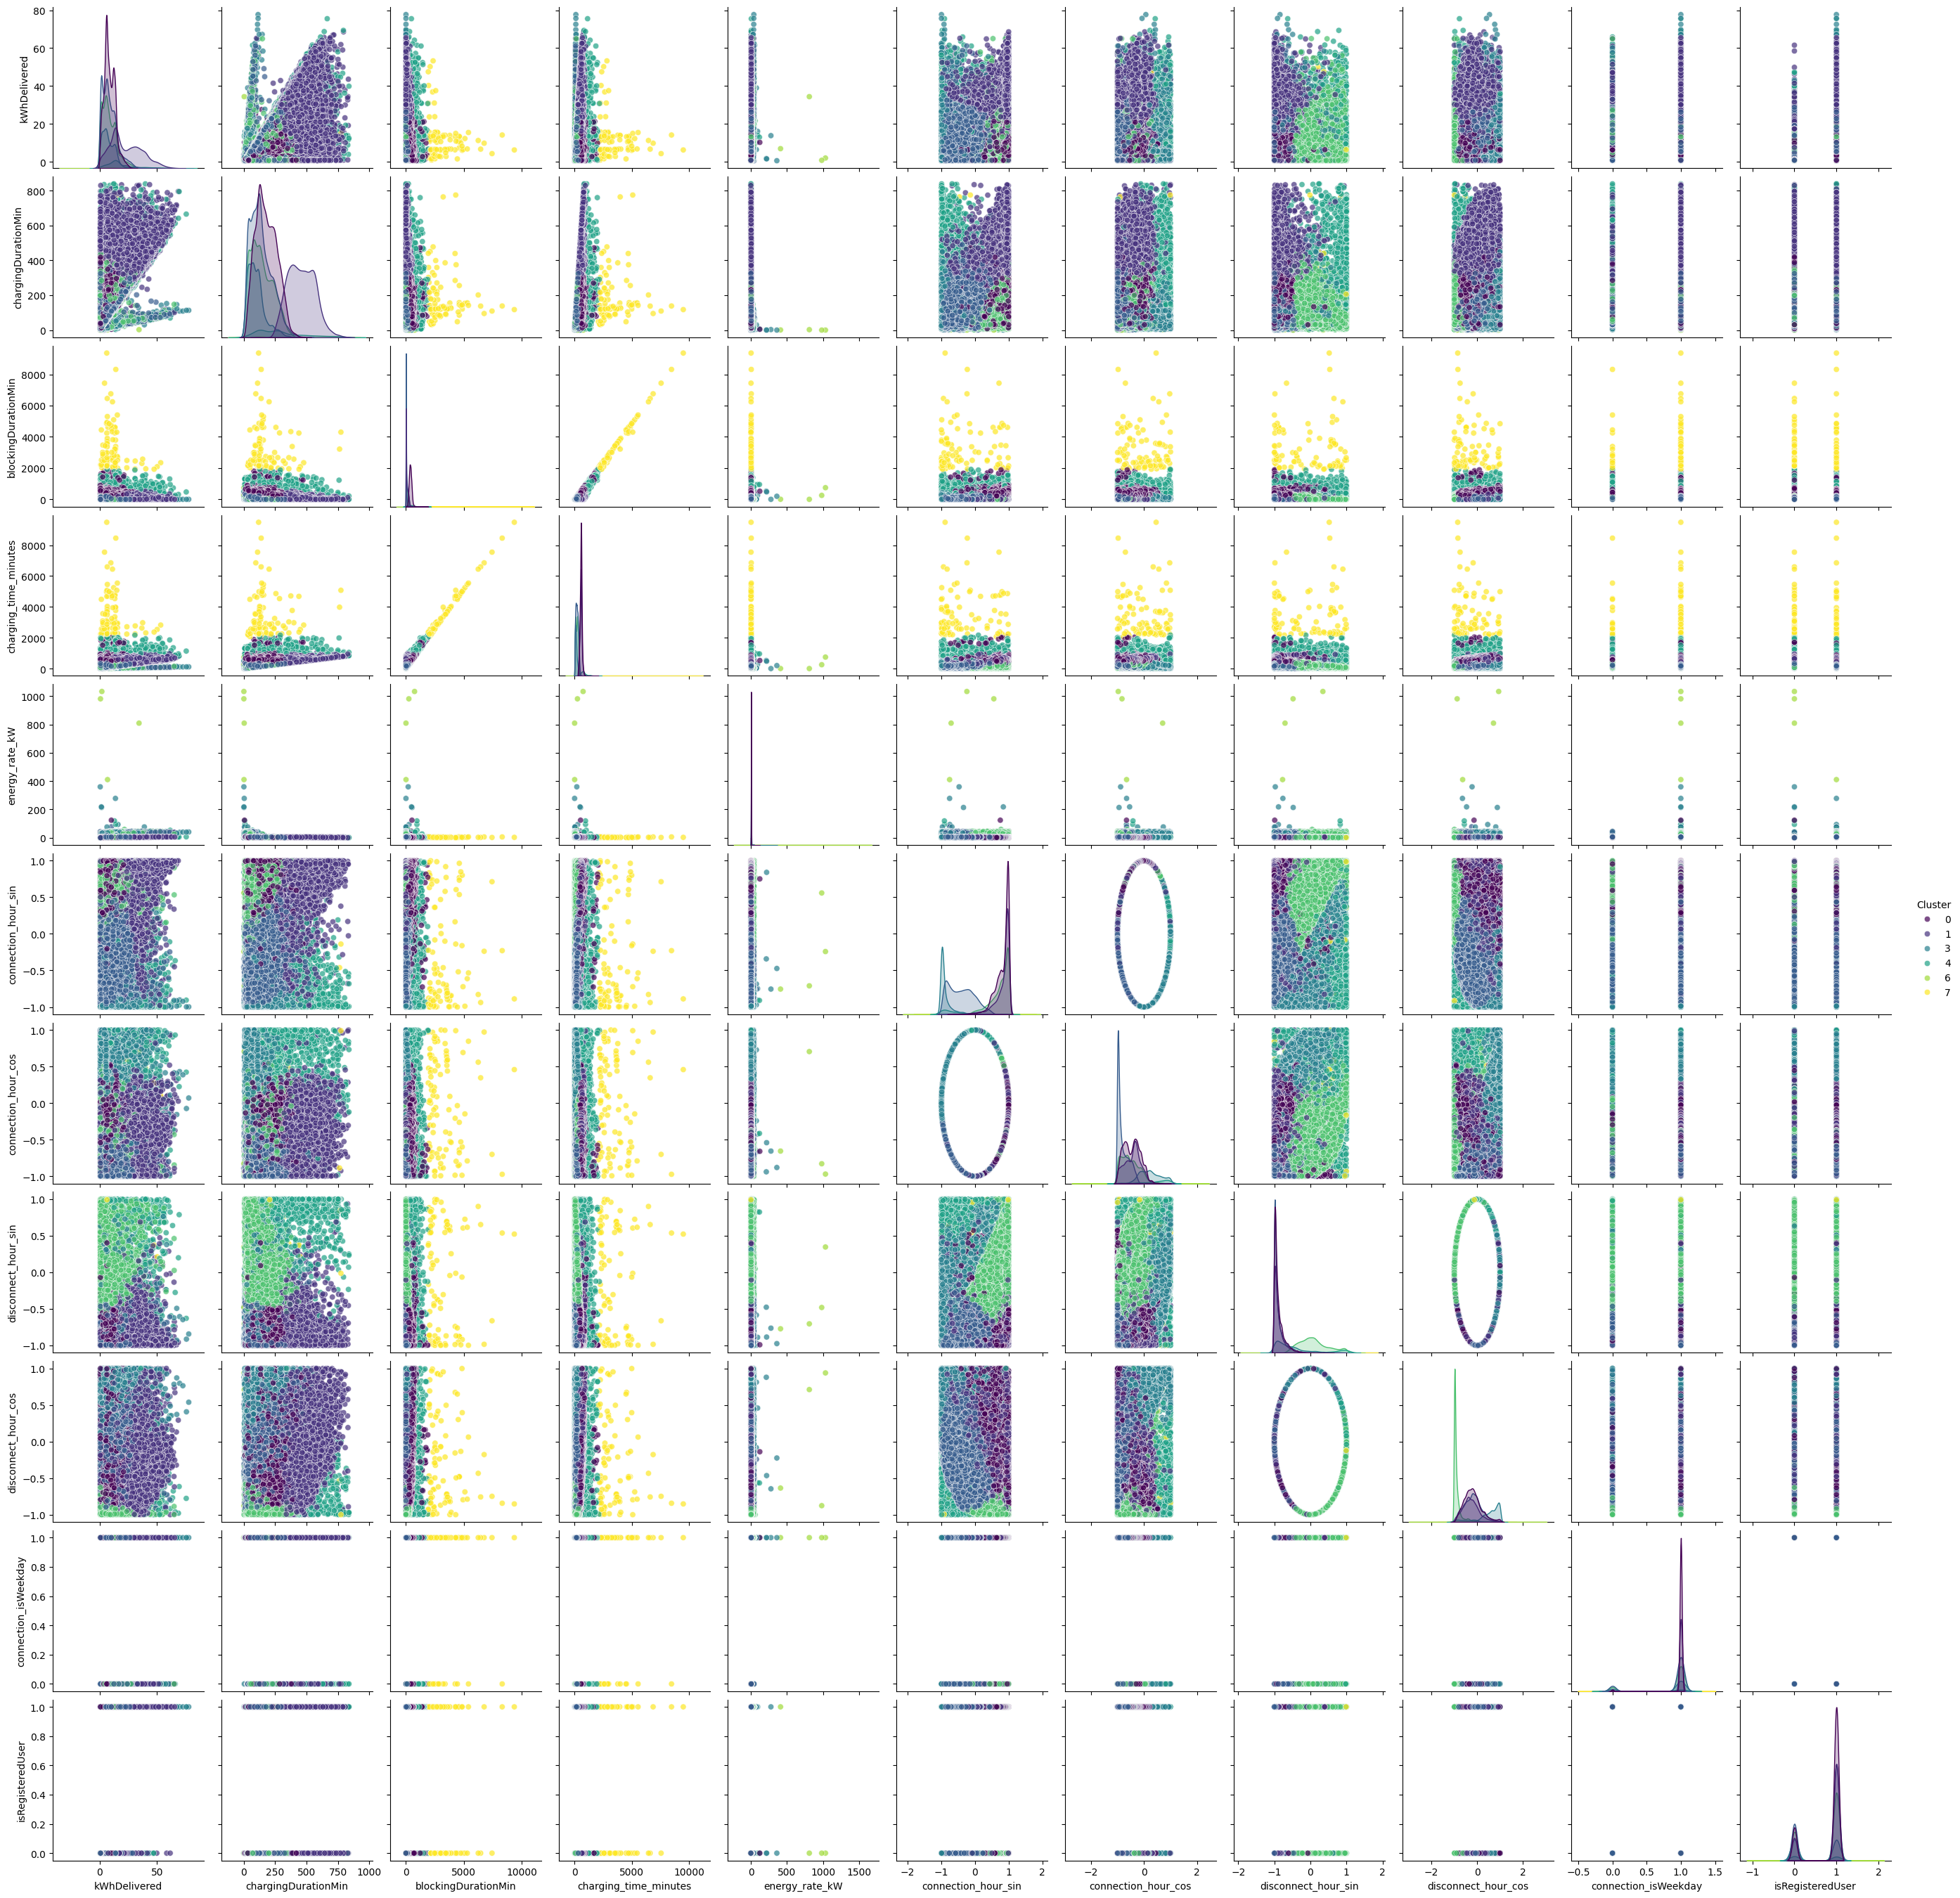

In [ ]:
# careful long runtime
#sns.pairplot(df, hue='Cluster', palette='viridis', plot_kws={'alpha':0.7})